# 03 · Base commune des métaheuristiques

**Modèle.** Une métaheuristique est une fonction `run(problem, rng, **params)` qui produit une suite de solutions évaluées $s_1, s_2, \dots, s_B$. Seul l'appel à $f$ consomme le budget $B$ ; $C$ est gratuit.

| Appel | Mathématique | Coût |
|---|---|---|
| `problem.fitness(mapping)`, `problem.fitness_of(permutation)` | $f(s)$ | 1 évaluation ; au-delà de $B$, l'exception `BudgetExhausted` arrête l'algorithme |
| `problem.surrogate(mapping)`, `problem.surrogate_of(permutation)` | $C(s)$ | gratuit |
| `problem.best_cost`, `problem.best_mapping` | $b_t = \min_{k \le t} f(s_k)$ et son placement | suivis automatiquement |

Représentation : $\sigma \in \mathfrak{S}_m$, $s = (\sigma(0), \dots, \sigma(n-1))$ ; voisinage par transposition $\sigma \circ (a\ b)$ avec $a < n$ (`optimizer.representation`).

**Mesures de performance.** On fait une exécution par graine $g$ ; la meilleure valeur finale est $b_B^{(g)}$.
- **Courbe de convergence** : $t \mapsto \frac{1}{G} \sum_g b_t^{(g)}$, avec la bande $[\min_g b_t^{(g)}, \max_g b_t^{(g)}]$.
- **Tableau** : moyenne ± écart-type de $b_B^{(g)}$, et entre parenthèses le meilleur.

In [1]:
import numpy as np
import pandas as pd

from goc.paths import RESULTS_ROOT
# Lancement d'exécutions, tableaux de résultats, sauvegarde, écriture des fichiers solutions.
from optimizer import history_frame, results_frame, run_algorithm, run_grid, save_results, write_result_if_better
# Deux algorithmes de référence fournis.
from optimizer.algorithms import identity, random_search
from optimizer.representation import random_permutation

# Nom de ton groupe, utilisé dans le nom des fichiers solutions (GroupeX_Challenge_N.txt).
GROUP = "Groupe0"

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

In [3]:
def display_table(frame, value="best_cost"):
    """Tableau lisible : pour chaque algorithme (ligne) et instance (colonne), « moyenne ± écart-type (meilleur) »."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    # unstack met les instances en colonnes ; les noms de colonnes deviennent « inst. N ».
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")


def plot_convergence(history, instance_ids=None):
    """Meilleur coût trouvé en fonction du nombre d'évaluations, par instance (moyenne sur les graines, bande min/max)."""
    instance_ids = instance_ids or sorted(history["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=min(3, len(instance_ids)), width=4.6, height=3.2)
    for ax, instance_id in zip(axes, instance_ids):
        subset = history[history["instance_id"] == instance_id]
        for color, (algorithm, group) in zip(PALETTE * 2, subset.groupby("algorithm")):
            # Une colonne par graine, une ligne par numéro d'évaluation ; ffill complète les trous.
            curves = group.pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.5)
            ax.fill_between(curves.index, curves.min(axis=1), curves.max(axis=1), color=color, alpha=0.15)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations", fontsize=8)
        ax.set_ylabel("best fitness so far", fontsize=8)
        ax.legend()
    fig.suptitle("Convergence: mean over seeds, band = min/max", y=1.0)
    fig.tight_layout()
    return fig

## 1. Une exécution

`run_algorithm` crée le problème avec le budget $B$, lance l'algorithme jusqu'à `BudgetExhausted` et renvoie un `Result` : $s^\star$, $b_B$, l'historique $(t, f(s_t), b_t)$ et le temps.

In [4]:
# Recherche aléatoire sur l'instance 3, 60 vraies évaluations, graine 0.
result = run_algorithm(random_search.run, instance_id=3, budget=60, seed=0)
# Résumé de l'exécution (dictionnaire).
result.summary()

{'algorithm': 'random_search',
 'instance_id': 3,
 'seed': 0,
 'best_mapping': [1, 3, 15, 5, 8, 13, 6, 7, 4, 10],
 'best_cost': 149,
 'evaluations': 60,
 'seconds': 5.481046900036745,
 'params': {}}

## 2. Écrire un algorithme : exemple

**Filtrage par le substitut.** À chaque évaluation $k$, on tire $R$ permutations uniformes $\sigma_1, \dots, \sigma_R$ et on n'évalue que

$$
s_k = \arg\min_{r \le R} C(\sigma_r)
$$

Interprétation : c'est une recherche aléatoire biaisée vers les petits $C$, sans mémoire d'une évaluation à l'autre. C'est aussi la référence `surrogate_filtered` : une métaheuristique qui utilise $C$ doit au moins faire mieux qu'elle.

In [5]:
def surrogate_filtered_random(problem, rng, candidates=200):
    """Boucle : tirer `candidates` placements, n'évaluer que le meilleur selon le coût de distance (gratuit)."""
    while True:
        pool = [random_permutation(problem.m, rng) for _ in range(candidates)]
        # Seule la permutation de plus petit coût de distance consomme une vraie évaluation.
        problem.fitness_of(min(pool, key=problem.surrogate_of))

## 3. Comparer des algorithmes

`run_grid` lance chaque algorithme sur chaque instance et chaque graine, **à budget égal**. Ici $B = 40$ et 3 graines, pour une démonstration rapide ; la comparaison réelle est dans le notebook 99.

`identity` réévalue toujours le même placement : son $b_B$ est le minimum de $B$ tirages du bruit autour de $F(\mathrm{id})$. C'est la référence la plus simple.

In [6]:
# Algorithmes comparés : {nom: (fonction, paramètres)}.
ALGORITHMS = {
    "identity": (identity.run, {}),
    "random_search": (random_search.run, {}),
    "surrogate_filtered": (surrogate_filtered_random, {"candidates": 200}),
}
INSTANCES = [3, 6, 9]
SEEDS = [0, 1, 2]
BUDGET = 40

# 3 algorithmes × 3 instances × 3 graines = 27 exécutions de 40 évaluations.
results = run_grid(ALGORITHMS, INSTANCES, SEEDS, BUDGET)

[2/27] 7 s | last: identity, instance 3, seed 1 -> 141


[4/27] 13 s | last: identity, instance 6, seed 0 -> 83


[6/27] 16 s | last: identity, instance 6, seed 2 -> 77


[8/27] 21 s | last: identity, instance 9, seed 1 -> 137


[10/27] 26 s | last: random_search, instance 3, seed 0 -> 157


[12/27] 34 s | last: random_search, instance 3, seed 2 -> 160


... (4 outputs left out)

[22/27] 60 s | last: surrogate_filtered, instance 6, seed 0 -> 41


[24/27] 63 s | last: surrogate_filtered, instance 6, seed 2 -> 38


[26/27] 68 s | last: surrogate_filtered, instance 9, seed 1 -> 106


[27/27] 71 s | last: surrogate_filtered, instance 9, seed 2 -> 110


In [7]:
# Une ligne par exécution, puis le tableau comparatif lisible.
frame = results_frame(results)
summary_table = display_table(frame)
summary_table

instance_id,inst. 3,inst. 6,inst. 9
algorithm,,,
identity,141.0 ± 0.0 (141),79.0 ± 2.8 (77),137.0 ± 0.0 (137)
random_search,157.3 ± 2.1 (155),47.0 ± 3.6 (42),105.7 ± 3.7 (101)
surrogate_filtered,147.0 ± 3.6 (142),39.0 ± 1.4 (38),105.3 ± 4.1 (100)


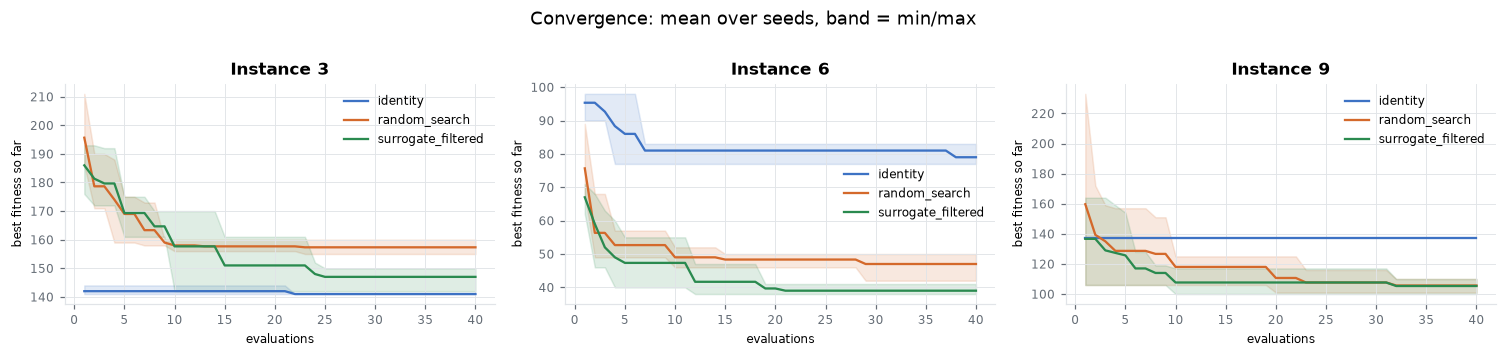

In [8]:
plot_convergence(history_frame(results));

## 4. Enregistrer

- `save_results` enregistre les exécutions, avec leur historique, dans `results/`.
- `write_result_if_better` écrit $s^\star$ et son coût au format du rendu (`GroupeX_Challenge_N.txt`) dans `solutions/`, **seulement si** ce coût est inférieur à celui déjà enregistré.

In [9]:
# Sauvegarde de toutes les exécutions dans results/.
save_results(results, RESULTS_ROOT / "template_demo.jsonl")
for instance_id in INSTANCES:
    # Meilleure exécution sur cette instance, tous algorithmes et graines confondus.
    best = min((r for r in results if r.instance_id == instance_id), key=lambda r: r.best_cost)
    path, written, previous = write_result_if_better(best, group=GROUP)
    status = "written" if written else f"kept existing file (cost {previous:g} is not worse)"
    print(f"instance {instance_id}: {best.algorithm} found {best.best_cost} -> {path.name}: {status}")

instance 3: identity found 141 -> Groupe0_Challenge_3.txt: kept existing file (cost 122 is not worse)
instance 6: surrogate_filtered found 38 -> Groupe0_Challenge_6.txt: kept existing file (cost 25 is not worse)
instance 9: surrogate_filtered found 100 -> Groupe0_Challenge_9.txt: kept existing file (cost 51 is not worse)


## 5. Ajouter une métaheuristique au projet

1. Crée `optimizer/algorithms/my_metaheuristic.py` avec une variable `name = "my_metaheuristic"` et une fonction `run(problem, rng, **params)`.
2. Ajoute-la dans le dictionnaire `ALGORITHMS` de `optimizer/algorithms/__init__.py`.
3. Étudie-la dans son propre notebook, puis ajoute-la au dictionnaire `CONTENDERS` du notebook `99_comparison` pour la comparer à toutes les autres.